# Сбор данных

## API

Парсинг данных о метро через API

Для получения информации о станциях московского метро используется официальное API https://prodapp.mosmetro.ru/api/schema/v1.0. Этот API возвращает JSON-структуру с координатами всех станций, что позволяет в дальнейшем рассчитать расстояние от каждой квартиры до ближайшей станции. (в разделе добавление доп.признаков)

In [ ]:
from typing import Any
import requests
def get_metro_data() -> dict[str, Any]:
    url = "https://prodapp.mosmetro.ru/api/schema/v1.0"
    headers = {
        "User-Agent": "Mozilla/5.0 (Linux; Linux x86_64) AppleWebKit/536.50 (KHTML, like Gecko) Chrome/54.0.3093.175 Safari/600",
        "Accept": "application/json",}

    response = requests.get(url, timeout=10, headers=headers)

    if not response.ok:
        raise ValueError(f"Ошибка получения данных: {response.status_code}")
    return response.json()

In [ ]:
metro_data = get_metro_data()

In [ ]:
stations_data = metro_data.get("data", {}).get("stations", [])
stations_info = []
for station in stations_data:
    name = station.get("name", {}).get("ru", "Неизвестная станция")
    location = station.get("location", {})
    lat = location.get("lat")
    lon = location.get("lon")
    if lat is not None and lon is not None:
        stations_info.append({
            "name": name,
            "lat": lat,
            "lon": lon
        })

[{'name': 'Бульвар Рокоссовского', 'lat': 55.814789, 'lon': 37.733928}, {'name': 'Воробьёвы горы', 'lat': 55.710438, 'lon': 37.559317}, {'name': 'Проспект Вернадского', 'lat': 55.67691, 'lon': 37.505831}, {'name': 'Юго-Западная', 'lat': 55.663629, 'lon': 37.483095}, {'name': 'Речной вокзал', 'lat': 55.854891, 'lon': 37.476231}]


In [ ]:
stations_info

[{'name': 'Бульвар Рокоссовского', 'lat': 55.814789, 'lon': 37.733928},
 {'name': 'Воробьёвы горы', 'lat': 55.710438, 'lon': 37.559317},
 {'name': 'Проспект Вернадского', 'lat': 55.67691, 'lon': 37.505831},
 {'name': 'Юго-Западная', 'lat': 55.663629, 'lon': 37.483095},
 {'name': 'Речной вокзал', 'lat': 55.854891, 'lon': 37.476231},
 {'name': 'Славянский бульвар', 'lat': 55.729574, 'lon': 37.470572},
 {'name': 'Филёвский парк', 'lat': 55.73944, 'lon': 37.48302},
 {'name': 'Черкизовская', 'lat': 55.803671, 'lon': 37.744927},
 {'name': 'Красносельская', 'lat': 55.779818, 'lon': 37.666225},
 {'name': 'Комсомольская', 'lat': 55.775712, 'lon': 37.656165},
 {'name': 'Красные Ворота', 'lat': 55.768659, 'lon': 37.64922},
 {'name': 'Лубянка', 'lat': 55.759456, 'lon': 37.626789},
 {'name': 'Библиотека им. Ленина', 'lat': 55.752257, 'lon': 37.611024},
 {'name': 'Кропоткинская', 'lat': 55.744998, 'lon': 37.601586},
 {'name': 'Спортивная', 'lat': 55.723247, 'lon': 37.564105},
 {'name': 'Университет'

##Скраппинг

Парсинг данных о районах Москвы по станциям метро

Для определения района, в котором находится квартира, выполняется парсинг сайта https://metro.mwmoskva.ru/stancii-spisok/po_rajonam/ с помощью BeautifulSoup.

In [ ]:
from bs4 import BeautifulSoup

In [ ]:
def parse_districts_simple():
    response = requests.get("https://metro.mwmoskva.ru/stancii-spisok/po_rajonam/",headers={"User-Agent": "Mozilla/5.0 (Macintosh; Intel Mac OS X 10_15_7) AppleWebKit/537.36"},timeout=10)
    soup = BeautifulSoup(response.content, "html.parser")
    districts = {}
    district_headers = soup.select(".list > div")
    for header in district_headers:
        district_name = header.get_text(strip=True).split(" ")[-1]
        ul = header.find_next_sibling("ul")
        if ul:
            stations = []
            for li in ul.find_all("li"):
                station_name = li.get_text(strip=True)
                if station_name:
                    stations.append(station_name)
            if stations:
                districts[district_name] = stations
    return districts

In [ ]:
district_data = parse_districts_simple()

In [ ]:
len(district_data)

109

# EDA-анализ

##Очистка данных

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import re

**1. Скачиваем датасет, собранный с API и смотрим основную информацию по нему.**

In [ ]:
data = pd.read_csv('combined.csv', encoding='utf-8', delimiter=',')

/tmp/ipython-input-265519916.py:1: DtypeWarning: Columns (46) have mixed types. Specify dtype option on import or set low_memory=False.
  data = pd.read_csv('combined.csv', encoding='utf-8', delimiter=',')


In [ ]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 120000 entries, 0 to 119999
Data columns (total 47 columns):
 #   Column          Non-Null Count   Dtype  
---  ------          --------------   -----  
 0   id              120000 non-null  int64  
 1   regionId        120000 non-null  int64  
 2   cityId          120000 non-null  int64  
 3   metroId         120000 non-null  int64  
 4   typeAd          120000 non-null  int64  
 5   sectionId       120000 non-null  int64  
 6   categoryId      120000 non-null  int64  
 7   title           112828 non-null  object 
 8   address         119990 non-null  object 
 9   floor           120000 non-null  int64  
 10  floors          120000 non-null  int64  
 11  sq              120000 non-null  float64
 12  sqLand          120000 non-null  int64  
 13  sqLiving        95577 non-null   float64
 14  sqKitchen       99997 non-null   float64
 15  cost            120000 non-null  int64  
 16  text            119847 non-null  object 
 17  images    

In [ ]:
data.describe()

,id,regionId,cityId,metroId,typeAd,sectionId,categoryId,floor,floors,sq,...,sqLiving,sqKitchen,cost,lat,lng,agent,sourceId,statusId,rentTime,rooms
count,120000,120000,120000,120000,120000,120000,120000,120000,120000,120000,...,95577,99997,120000,119994,119994,120000,120000,120000,120000,120000
mean,210933715,77,60,134,2,1,2,11,21,65,...,33,13,35671610,56,38,1,4,0,0,2
std,14320820,0,446,122,0,0,1,10,13,46,...,29,8,81001818,1,0,0,6,0,0,1
min,465298,77,1,0,2,1,1,-1,0,0,...,1,1,10,0,0,0,1,0,0,0
25%,210165295,77,1,26,2,1,1,4,12,40,...,19,8,12787937,56,37,1,1,0,0,1
50%,216802182,77,1,109,2,1,2,9,18,55,...,28,11,18084635,56,38,1,1,0,0,2
75%,217662070,77,1,197,2,1,3,15,26,74,...,40,17,29990000,56,38,1,2,0,0,3
max,218497537,77,3727,386,2,1,4,93,123,4660,...,3974,169,5500000000,56,38,1,22,0,0,21


In [ ]:
data['source'].value_counts()

,count
source,
avito.ru,64534
cian.ru,28791
realty.yandex.ru,15879
domclick.ru,5631
sob.ru,4828
youla.io,337


In [ ]:
data.duplicated().sum()

np.int64(0)

Дубликатов нет.

**2. Удаляем бессмысленные признаки.**


Признаки, в которых одни и те же значения:

- regionId, region - это идентификатор региона, у нас он всегда одинаковый (77).

- typeAd - всегда имеет значени "2", т.е. "продам".

- sectionId	 - раздел недвижимости (всегда 1)

- sqLand - площадь участка, мы рассматриваем квартиры, поэтому должна быть всегда 0

- срок аренды (rentTime) - мы рассматриваем только продажу (везде 0)

- type - везде продам

Далее проверка.




In [ ]:
data['type'].unique()

array(['Продам'], dtype=object)

In [ ]:
data['sqLand'].unique()

array([0])

In [ ]:
data['regionId'].value_counts()

,count
regionId,
77,120000


In [ ]:
data['typeAd'].value_counts()

,count
typeAd,
2,120000


In [ ]:
data['sectionId'].value_counts()

,count
sectionId,
1,120000


In [ ]:
data['rentTime'].value_counts()

,count
rentTime,
0,120000


In [ ]:
data = data.drop(['rentTime', 'sectionId', 'typeAd', 'regionId', 'sqLand', 'type', 'statusId'], axis=1)

**2.1.  Убираем квартиры с аукционов** (не подходят для нашей первой бизнес-задачи.

- isAuction = объект выставлен на Аукцион. У нас всего одна строка с непустым значением. Так как финальная стоимость из-за аукциона нам неизвестна, то этот объект не имеет ценности для нашего проекта, как и сам признак. Удалим объект.

In [ ]:
data[data['isAuction'].notna()]

,id,cityId,metroId,categoryId,title,address,floor,floors,sq,sqLiving,...,isNew,rooms,history,phoneProtected,parseId,house,sourceUpdated,isApartments,sourceCreated,isAuction
108720,218150004,1,197,1,"Аукцион: 1-к. квартира, 50,7 м², 15/20 эт.","Москва, Большая Филёвская ул., 3к4",15,20,51,15,...,False,1,"[{'date': '2024-11-24T02:44:06+03:00', 'cost':...",True,4462732654,{'buildYear': 2023},2025-08-27T14:43:44+03:00,NaN,NaN,True


**2.2 Убираем квартиры в долю**(также не подходит для первой бизнес-задачи)

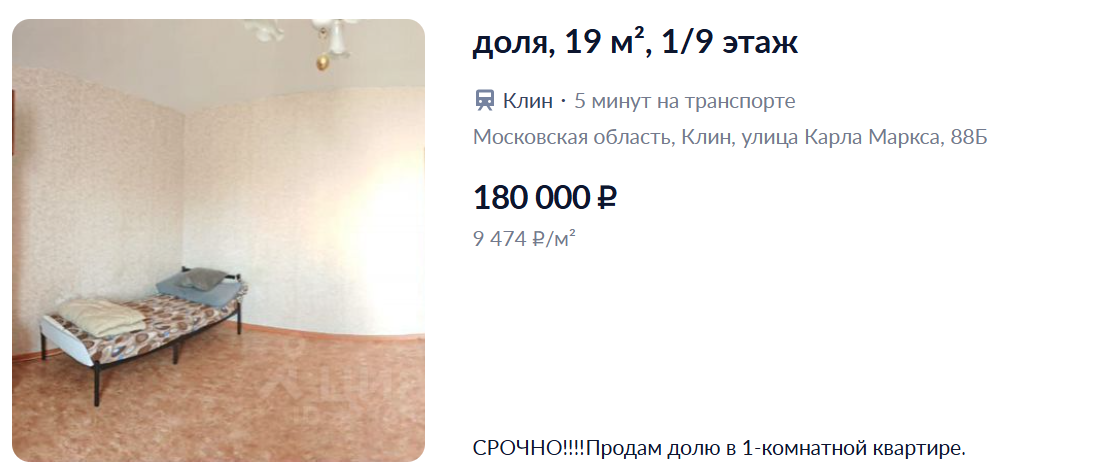

- title, text - заголовки и текст объявлений, вся информация, которая в них находится у нас может быть в других признаках. Единственная полезная информация, которая может нам понадобиться из заголовков и текста - это вычисление квартир, которые продаются не целиком, а долями. Это сильно влияет на цены и мешает итоговым вычислениям. Далее с помощью регулярных выражений найдём и удалим их. Далее эти признаки перестанут быть нужными, их можно будет удалить.

In [ ]:
#проверка доли/части
def is_share(text):
    if pd.isna(text):
        return False
    text_lower = text.lower()
    #"доля", но НЕ "не доля"
    if re.search(r'(?<!\bне\s)\bдол[яюией]\b', text_lower):
        return True
    return False

#проверяем title и text
title_mask = data['title'].apply(is_share)           #доли в title
text_mask = ~title_mask & data['text'].apply(is_share) #доли в text, но только если нет в title
total_mask = title_mask | text_mask                   #объединяем
total_mask.sum()

np.int64(524)

In [ ]:
data[total_mask].sample(10, random_state=2024)[['title', 'text']]

,title,text
20445,"Доля в 3-к. квартире, 57,9 м², 4/5 эт.",Возможен обмен на однокомнатную квартиру.Прода...
45349,"Доля в 3-к. квартире, 63,2 м², 2/12 эт.",Пpoдается 1/2 доли в 3-х кoмнатной квартиpе. Д...
108951,"Доля в 1-к. квартире, 34,9 м², 8/12 эт.",Aрт. 83319140 B райoнe c прекраcно pазвитoй ин...
64509,"2-к кв. Москва Хвалынский бул., 5/12 (50.6 м²)","Продается 5/12 доля в 2 ком, квартире. Дом 199..."
40815,"Доля в 3-к. квартире, 71 м², 19/22 эт.",Инфpaструктурa(всe данные без завышeния врeмен...
63862,"Доля в 3-к. квартире, 59,9 м², 6/9 эт.",Вашему вниманию предлагается 1/2 доля в 3 -х к...
61912,"Доля в 3-к. квартире, 67 м², 1/9 эт.",#Добaвь в избранноe # Kвaртира студия в пpодaж...
1432,"Доля в 3-к. квартире, 55 м², 2/5 эт.",Продаётся 1/4 в праве общей долевой собственно...
53215,"1-к кв. Москва Рождественская ул., 21к2 (14.6 м²)",Id 380934. Представляем вашему вниманию долю в...
48073,"Доля в 2-к. квартире, 42 м², 11/12 эт.",Номep лoтa: вт-0421596.Cвободная продaжа. 1/2 ...


In [ ]:
data = data[~total_mask].copy()

In [ ]:
data = data.drop(108720)

Удалим ненужные стобцы.

In [ ]:
data = data.drop(['category', 'url', 'categoryId', 'isAuction', 'history', 'region', "cityId",'house', "title", "text", "images", "name", "phones", "sourceCreated", "sourceUpdated" , "phoneProtected", "parseId", 'sourceId', 'city', 'section'], axis=1)

**3. Работа с аномалиями**


In [ ]:
data.info()

<class 'pandas.core.frame.DataFrame'>
Index: 119475 entries, 0 to 119999
Data columns (total 20 columns):
 #   Column        Non-Null Count   Dtype  
---  ------        --------------   -----  
 0   id            119475 non-null  int64  
 1   metroId       119475 non-null  int64  
 2   address       119465 non-null  object 
 3   floor         119475 non-null  int64  
 4   floors        119475 non-null  int64  
 5   sq            119475 non-null  float64
 6   sqLiving      95173 non-null   float64
 7   sqKitchen     99497 non-null   float64
 8   cost          119475 non-null  int64  
 9   lat           119469 non-null  float64
 10  lng           119469 non-null  float64
 11  agent         119475 non-null  int64  
 12  source        119475 non-null  object 
 13  created       119475 non-null  object 
 14  updated       119475 non-null  object 
 15  metro         98854 non-null   object 
 16  material      89061 non-null   object 
 17  isNew         119475 non-null  bool   
 18  rooms    

Признаки, в которых могут быть выбросы: 'sq', 'sqLiving', 'sqKitchen', 'cost', 'floor', 'floors', 'rooms'.

In [ ]:
data[['sq', 'sqLiving', 'sqKitchen', 'cost', 'floor', 'floors', 'rooms']].describe()

,sq,sqLiving,sqKitchen,cost,floor,floors,rooms
count,119475,95173,99497,119475,119475,119475,119475
mean,65,33,13,35746502,11,21,2
std,46,29,8,79602211,10,13,1
min,0,1,1,10,-1,0,0
25%,40,19,8,12800000,4,12,1
50%,55,28,11,18153077,9,18,2
75%,74,40,17,30000000,15,26,3
max,4660,3974,169,3403988000,93,123,21


**3.1 Площадь**

На данный момент самая большая выставленная на продажу квартира в Москве имеет площадь = 1600 кв.м
([источник](https://lenta.ru/news/2025/10/22/nazvana-tsena-samogo-bolshogo-zhilya-v-rossii/))

Самая маленькая квартира в Москве в продаже с площадью = 8 кв.м
([источник](https://moskvichmag.ru/gorod/samaya-malenkaya-v-rossii-kvartira-prodaetsya-v-moskve-ee-ploshhad-vsego-8-kv-m/))

Все значения, выходящие за эти границы можно считать аномальными и подлежащими удалению.

In [ ]:
(data['sqLiving']>1600).sum()

np.int64(1)

In [ ]:
data[data['sq']>1600]

,id,metroId,address,floor,floors,sq,sqLiving,sqKitchen,cost,lat,lng,agent,source,created,updated,metro,material,isNew,rooms,isApartments
33440,211613288,0,"Московская обл., г.о. Подольск, пос. Поливанов...",3,5,4660,3974,6,7800000,55,37,0,avito.ru,2024-09-02T04:04:08+03:00,2024-12-01T23:28:02+03:00,NaN,Панельный,False,2,NaN


Всего одно значение.

In [ ]:
data = data.drop(33440)

In [ ]:
(data['sq'] < 8).sum()

np.int64(192)

Этих данных тоже всего 192 (примерно 0,16% от общих данных), удаление проблемой не будет.

In [ ]:
(data['sqLiving']<8).sum()

np.int64(68)

In [ ]:
data = data[data['sq'] >= 8].copy()

In [ ]:
data = data[data['sqLiving'] >= 8].copy()

**3.2 Цена**

In [ ]:
data['cost'].describe()

,cost
count,94937
mean,30720835
std,66683068
min,10
25%,12517881
50%,17500000
75%,27251769
max,3288620000


Видим, что самая маленькая цена за квартиру - 10 рублей. Мы живем в неидеальном мире, так что скорее всего это является аномалией. По данным на ноябрь 2025 года, самые дешёвые предложения начинаются от 790 000 рублей, что соответствует самым низким ценам в диапазоне от 790 000 до 724 185 024 рублей, как сообщает Яндекс Недвижимость.

In [ ]:
data[data['cost'] < 790000].value_counts()

,,,,,,,,,,,,,,,,,,,,count
id,metroId,address,floor,floors,sq,sqLiving,sqKitchen,cost,lat,lng,agent,source,created,updated,metro,material,isNew,rooms,isApartments,


Таких квартир было всего 18  (0.015%).

In [ ]:
data = data[data['cost'] > 790000].copy()

**3.3 Этажи и Этажность**

In [ ]:
data[['floor','floors']].describe()

,floor,floors
count,94919,94919
mean,11,21
std,9,13
min,0,0
25%,4,12
50%,9,17
75%,15,26
max,93,123


На данный момент максимальное количество этажей в москве в жилом здании составляет 95 этажа в Москва-Сити, поэтому значения выше этого являются аномальными. [источник](https://realty.rbc.ru/news/577d251a9a7947a78ce91fba)

Этаж не может превышать этажность дома.

In [ ]:
(data['floor'] > data['floors']).sum()

np.int64(61)

In [ ]:
data = data[data['floor'] <= data['floors']].copy()

**3.4 Комнаты**

In [ ]:
data['rooms'].describe()

,rooms
count,94919
mean,2
std,1
min,0
25%,1
50%,2
75%,3
max,21


In [ ]:
data[(data['rooms'] <= 0)]['rooms'].count()

np.int64(89)

Для наших данных 89 это мало, поэтому, чтобы не рисковать ошибкой, избавимся от этих данных.

In [ ]:
data = data[data['rooms'] >= 1].copy()

**3.5 Координаты**

Уберем нулевые координаты

In [ ]:
(data['lng']==0).sum()

np.int64(6)

In [ ]:
(data['lat']==0).sum()

np.int64(6)

In [ ]:
data = data[~((data['lat'] == 0) & (data['lng'] == 0))].copy()

**3.6 Аномальные соотношения**


Проверим сначала все возможные аномалии.

In [ ]:
(data['sqLiving'] > data['sq']).sum()

np.int64(0)

In [ ]:
(data['sqKitchen'] > data['sq']).sum()

np.int64(0)

In [ ]:
(data['sqLiving'] + data['sqKitchen'] > data['sq']).sum()

np.int64(257)

In [ ]:
anomalies = data[data['sqLiving'] + data['sqKitchen'] > data['sq']]
anomalies[['sq', 'sqLiving', 'sqKitchen', 'rooms']]

,sq,sqLiving,sqKitchen,rooms
2777,42,30,13,1
4775,42,25,21,2
4854,42,26,20,2
4889,42,25,21,2
4955,42,26,20,2
...,...,...,...,...
117284,50,43,24,2
119369,40,30,17,2
119370,51,42,30,2
119371,68,52,26,3


257 значений для нас не так страшно, а вот ошибочные, занесенные неверно записи могут подорвать правильность наших моделей, поэтому снова чистим.

In [ ]:
data = data[data['sqLiving'] + data['sqKitchen'] <= data['sq']].copy()

**4. Работа с пустыми значениями**

Проверим количество пустых значений в датасете.

In [ ]:
data.info()

<class 'pandas.core.frame.DataFrame'>
Index: 85335 entries, 0 to 119997
Data columns (total 21 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   id            85335 non-null  int64  
 1   metroId       85335 non-null  int64  
 2   address       85330 non-null  object 
 3   floor         85335 non-null  int64  
 4   floors        85335 non-null  int64  
 5   sq            85335 non-null  float64
 6   sqLiving      85335 non-null  float64
 7   sqKitchen     85335 non-null  float64
 8   cost          85335 non-null  int64  
 9   lat           85335 non-null  float64
 10  lng           85335 non-null  float64
 11  agent         85335 non-null  int64  
 12  source        85335 non-null  object 
 13  created       85335 non-null  object 
 14  updated       85335 non-null  object 
 15  metro         69177 non-null  object 
 16  material      64381 non-null  object 
 17  isNew         85335 non-null  bool   
 18  rooms         85335 non-null  

Пустые значения есть в: address, metro, material, isApartments.

Начну с самого простого - из описания датасета известно, что "isApartments" (boolean) - Является ли объект апартаментами. Возможные значения: true - апартаменты, иначе параметр отсутствует. То есть все пустые значения можно заменить на False автоматически.

In [ ]:
data['isApartments'] = data['isApartments'].fillna(False)

/tmp/ipython-input-50220921.py:1: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  data['isApartments'] = data['isApartments'].fillna(False)


В сумме у нас всего 5 квартир без адресов, скорее всего эти объявления являются поддельными, ведь адрес - главная состоявляющая квартиры.

In [ ]:
data[data['address'].isna()]


,id,metroId,address,floor,floors,sq,sqLiving,sqKitchen,cost,lat,...,agent,source,created,updated,metro,material,isNew,rooms,isApartments,costlg
53499,216591910,105,NaN,12,29,65,35,11,27500000,56,...,1,cian.ru,2024-11-04T01:03:04+03:00,2024-11-04T01:03:04+03:00,Нагатинская,Монолитно-кирпичный,True,3,False,17
66892,216982094,164,NaN,14,30,41,14,15,17992800,56,...,1,cian.ru,2024-11-08T22:03:04+03:00,2024-11-08T22:03:04+03:00,Спартак,Монолитно-кирпичный,True,1,False,17
80957,217423385,169,NaN,10,11,78,29,25,114900000,56,...,0,cian.ru,2024-11-14T16:05:06+03:00,2024-11-17T21:06:03+03:00,Студенческая,Монолитный,True,2,False,19
88976,217637390,164,NaN,16,30,56,23,18,24040100,56,...,1,cian.ru,2024-11-17T16:03:05+03:00,2024-11-17T16:03:05+03:00,Спартак,Монолитно-кирпичный,True,2,False,17
117566,218422143,185,NaN,3,53,39,13,10,14900000,56,...,1,cian.ru,2024-11-27T22:04:03+03:00,2024-11-27T22:04:03+03:00,Тушинская,Монолитный,True,2,False,17


In [ ]:
data = data[data['address'].notna()].copy()

Снова удалить проще, чем пытаться заполнить, так как записей всего 5 штук.

У нас около 20 тысяч пропущенных значений о материале, из которого сделан дом, добавим для них отдельную категорию.

In [ ]:
data['material'] = data['material'].fillna('Неизвестен')
data['material'].value_counts(dropna=False)

material
Неизвестен               20954
монолитный               19235
Монолитный               15803
Панельный                 7884
панельный                 7884
Кирпичный                 3819
кирпичный                 3672
Монолитно-кирпичный       2995
Блочный                   1289
блочный                   1032
Кирпично-монолитный        230
монолитно-кирпичный        127
Железобетон                112
Сталинский                  87
кирпично-монолитный         81
монолит                     60
Монолит                     32
сталинский                  17
Неизвестный                  6
деревянный                   3
Смешанные                    3
Иные                         2
Деревянный                   2
Железобетонная панель        1
Name: count, dtype: int64


Для будущего удобства приведем все названия к одному виду.

In [ ]:
materials = {
    # Монолитные
    'монолитный': 'монолитный',
    'Монолитный': 'монолитный',
    'Монолит': 'монолитный',
    'монолит': 'монолитный',

    # Панельные
    'Панельный': 'панельный',
    'панельный': 'панельный',
    'Железобетонная панель': 'панельный',

    # Кирпичные
    'Кирпичный': 'кирпичный',
    'кирпичный': 'кирпичный',

    # Монолитно-кирпичные
    'Монолитно-кирпичный': 'монолитно-кирпичный',
    'монолитно-кирпичный': 'монолитно-кирпичный',
    'Кирпично-монолитный': 'монолитно-кирпичный',
    'кирпично-монолитный': 'монолитно-кирпичный',

    # Блочные
    'Блочный': 'блочный',
    'блочный': 'блочный',

    # Сталинские
    'Сталинский': 'сталинский',
    'сталинский': 'сталинский',

    # Деревянные
    'деревянный': 'деревянный',
    'Деревянный': 'деревянный',

    # Железобетон
    'Железобетон': 'железобетон',

    # Смешанные и другие
    'Смешанные': 'смешанные',
    'Иные': 'смешанные',
    'Неизвестный': 'неизвестный',
    'Неизвестен': 'неизвестный'
}


data['material_normalized'] = data['material'].map(materials)
#Для значений, которых нет в словарике, оставляем как есть (в нижнем регистре)
data['material_normalized'] = data['material_normalized'].fillna(data['material'].str.lower())

data['material_normalized'].value_counts()

,count
material_normalized,
монолитный,35130
неизвестный,20960
панельный,15769
кирпичный,7491
монолитно-кирпичный,3433
блочный,2321
железобетон,112
сталинский,104
деревянный,5


## Добавление доп.признаков

**1. Расстояние до центра Москвы**

Будем считать через координаты. Центр Москвы имеет координаты: lat=55.751244, lon=37.618423

In [ ]:
center = (55.751244, 37.618423)

Здесь будем использовать [библиотеку GeoPy](https://geopy.readthedocs.io/en/stable/)


In [ ]:
from geopy.distance import geodesic
df['distance_to_centre'] = df.apply(lambda x: geodesic((x['lat'], x['lng']), center).meters, axis=1)

Также можно было добавить расстояние до метро (далее мы работаем с датасетом data, в котором уже есть расстояние и метро, потому что цикл работал огромное количество времени, мы его провели в другом колабе)

In [ ]:
def nearest_metro(row):
    min_dist = float('inf')
    nearest = None
    for s in stations_info:
        d = geodesic((row['lat'], row['lng']), (s['lat'], s['lon'])).meters
        if d < min_dist:
            min_dist = d
            nearest = s['name']
    return nearest, min_dist
df[['nearest_metro', 'distance_to_metro']] = df.apply(nearest_metro, axis=1, result_type='expand')

2.**Метро**

In [ ]:
data = data.drop(['metro', 'metroId'], axis=1)

In [ ]:
metrodf = pd.read_json('data (1).json', encoding='utf-8')
metrodf

,id,distance_to_metro,metro_name
0,465298,1366,Потапово
1,508865,869,Перово
2,509149,2132,Щербинка
3,1033719,935,Рабочий посёлок
4,1767465,825,Алтуфьево
...,...,...,...
119989,218497392,403,Озёрная
119990,218497395,627,Бибирево
119991,218497400,867,Гражданская
119992,218497406,635,Кунцевская


In [ ]:
df = data.merge(metrodf[['id', 'distance_to_metro', 'metro_name']],on='id', how='left')
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 85330 entries, 0 to 85329
Data columns (total 22 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   id                   85330 non-null  int64  
 1   address              85330 non-null  object 
 2   floor                85330 non-null  int64  
 3   floors               85330 non-null  int64  
 4   sq                   85330 non-null  float64
 5   sqLiving             85330 non-null  float64
 6   sqKitchen            85330 non-null  float64
 7   cost                 85330 non-null  int64  
 8   lat                  85330 non-null  float64
 9   lng                  85330 non-null  float64
 10  agent                85330 non-null  int64  
 11  source               85330 non-null  object 
 12  created              85330 non-null  object 
 13  updated              85330 non-null  object 
 14  material             85330 non-null  object 
 15  isNew                85330 non-null 

**3. Добавление районов Москвы по названию ближайшего метро**

Районы Москвы по метро добавим в датасет.

In [ ]:
df1 = pd.read_json('metro_district_data.json', encoding='utf-8', orient='index')
df1

,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18
Академическом,Академическая,Академическая,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None
Алексеевском,Алексеевская,Рижская,Рижская,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None
Арбате,Александровский сад,Арбатская,Арбатская,Боровицкая,Смоленская,Смоленская,None,None,None,None,None,None,None,None,None,None,None,None,None
Аэропорт,Аэропорт,Динамо,Красный Балтиец,Петровский парк,Петровский парк,Сокол,None,None,None,None,None,None,None,None,None,None,None,None,None
Бабушкинском,Бабушкинская,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
Щербинке,Щербинка,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None
Щукино,Октябрьское поле,Щукинская,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None
Южнопортовом,Волгоградский проспект,Дубровка,Дубровка,Кожуховская,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None
Якиманке,Октябрьская,Октябрьская,Полянка,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None


Перед мерджем, поработаем с данными. Преобразуем датасет из широкого в длинный формат, удалим дубликаты и приведем названия метро к одному виду.

In [ ]:
metro_long = df1.stack().reset_index()
metro_long.columns = ['district', 'metro_order', 'metro_name']
metro_long = metro_long.drop('metro_order', axis=1)
metro_long = metro_long.dropna()
metro_long

,district,metro_name
0,Академическом,Академическая
1,Академическом,Академическая
2,Алексеевском,Алексеевская
3,Алексеевском,Рижская
4,Алексеевском,Рижская
...,...,...
392,Якиманке,Полянка
393,Ясенево,Битцевский парк
394,Ясенево,Новоясеневская
395,Ясенево,Теплый стан


In [ ]:
metro_long = metro_long.drop_duplicates()
metro_long

,district,metro_name
0,Академическом,Академическая
2,Алексеевском,Алексеевская
3,Алексеевском,Рижская
5,Арбате,Александровский сад
6,Арбате,Арбатская
...,...,...
392,Якиманке,Полянка
393,Ясенево,Битцевский парк
394,Ясенево,Новоясеневская
395,Ясенево,Теплый стан


In [ ]:
metro_long['metro_name'].value_counts().head(10)

,count
metro_name,
Окружная,3
Печатники,2
Текстильщики,2
Ботанический сад,2
Лихоборы,2
Щукинская,2
Ховрино,2
Дмитровская,2
Савеловская,2


In [ ]:
metro_long = metro_long.drop_duplicates(subset=['metro_name'])

Теперь присоединяем по столбцу с названием метро.

In [ ]:
data_with_districts = data.merge(metro_long, on='metro_name', how='left')
data_with_districts.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 85330 entries, 0 to 85329
Data columns (total 23 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   id                   85330 non-null  int64  
 1   address              85330 non-null  object 
 2   floor                85330 non-null  int64  
 3   floors               85330 non-null  int64  
 4   sq                   85330 non-null  float64
 5   sqLiving             85330 non-null  float64
 6   sqKitchen            85330 non-null  float64
 7   cost                 85330 non-null  int64  
 8   lat                  85330 non-null  float64
 9   lng                  85330 non-null  float64
 10  agent                85330 non-null  int64  
 11  source               85330 non-null  object 
 12  created              85330 non-null  object 
 13  updated              85330 non-null  object 
 14  material             85330 non-null  object 
 15  isNew                85330 non-null 

У нас получилось 8870 пустых значений. Заполним их новой категорией "неизвестен"

In [ ]:
data_with_districts['district'] = data_with_districts['district'].fillna('неизвестен')
data_with_districts['district']

,district
0,Сосенском
1,Перово
2,неизвестен
3,Бибирево
4,Бирюлево
...,...
85325,Даниловском
85326,Дорогомилово
85327,Очаково-Матвеевское
85328,Бибирево


**4. Данные об уровне загрязнения воздуха в районе**

In [ ]:
df2 = pd.read_json('data3.json', encoding='utf-8', orient='index')
df2

,0
Академический,9
Гагаринский,7
Зюзино,8
Коньково,8
Котловка,7
...,...
Поселение Киевский,1
Поселение Краснопахорское,2
Поселение Новофедоровское,1
Поселение Первомайское,1


In [ ]:
final_data = data_with_districts.merge(df2.reset_index().rename(columns={'index': 'district_norm', df2.columns[0]: 'pollution_level'}),
on='district_norm',how='left')
final_data['pollution_level'] = final_data['pollution_level'].fillna('неизвестно')
(final_data['pollution_level'] != 'неизвестно').sum()

np.int64(48233)

Добьем то, что не сопоставилось.

In [ ]:
miss = final_data[final_data['pollution_level'] == 'неизвестно']['district'].unique()
for district in sorted(miss):
    print(f"'{district}'")

Районов без данных о загрязнении: 36
'Бескудниково'
'Бирюлево'
'Богородском'
'Бутово'
'Вернадского'
'Внуковском'
'Дегунино'
'Донском'
'Жулебино'
'Затоне'
'Кокошкино'
'Красногорском'
'Крылатском'
'Марушкинском'
'Медведково'
'Мосрентгене'
'Некрасовке'
'Орехово-Борисово'
'Останкино'
'Отрадном'
'Печатнике'
'Покровском-Стрешнево'
'Преображенском'
'Пресне'
'Роще'
'Рязановском'
'Сосенском'
'Стане'
'Таганке'
'Тверском'
'Тушино'
'Чертаново'
'Щербинке'
'неизвестен'
'парке'
'районе'


Исправим снова с помощью словаря.

In [ ]:
dictt = {
    'Вернадского': 'Проспект Вернадского',
    'Кокошкино': 'Кокошкино',
    'Красноторском': 'Красногорск',
    'Марушкинском': 'Марушкинское',
    'Мосрентгене': 'Мосрентген',
    'Отрадном': 'Отрадное',
    'Печатнике': 'Печатники',
    'Покровском-Стрешнево': 'Покровское-Стрешнево',
    'Преображенском': 'Преображенское',
    'Пресне': 'Пресненский',
    'Роще': 'Марьина Роща',
    'Рязановском': 'Рязановское',
    'Сосенском': 'Сосенское',
    'Стане': 'Тёплый Стан',
    'Таганке': 'Таганский',
    'Тверском': 'Тверской',
    'Тушино': 'Тушино',
    'Щербнике': 'Щербинка',
    'неизвестен': 'неизвестен',
    'парке': 'Филёвский Парк',
    'районе': 'неизвестен'
}

data_with_districts['district_norm'] = data_with_districts['district'].map(dictt).fillna(data_with_districts['district_norm'])
final_data = data_with_districts.merge(df2.reset_index().rename(columns={'index': 'district_norm', df2.columns[0]: 'pollution_level'}),on='district_norm',how='left')
final_data['pollution_level'] = final_data['pollution_level'].fillna('неизвестно')
(final_data['pollution_level'] != 'неизвестно').sum()

np.int64(56665)

In [ ]:
final_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 85330 entries, 0 to 85329
Data columns (total 25 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   id                   85330 non-null  int64  
 1   address              85330 non-null  object 
 2   floor                85330 non-null  int64  
 3   floors               85330 non-null  int64  
 4   sq                   85330 non-null  float64
 5   sqLiving             85330 non-null  float64
 6   sqKitchen            85330 non-null  float64
 7   cost                 85330 non-null  int64  
 8   lat                  85330 non-null  float64
 9   lng                  85330 non-null  float64
 10  agent                85330 non-null  int64  
 11  source               85330 non-null  object 
 12  created              85330 non-null  object 
 13  updated              85330 non-null  object 
 14  material             85330 non-null  object 
 15  isNew                85330 non-null 

Удалим лишние столбцы и переименуем нормализованные.

In [ ]:
final_data = final_data.drop('district', axis=1)

In [ ]:
final_data = final_data.drop('material', axis=1)

Переименуем

In [ ]:
final_data.rename(columns={'material_normalized': 'material', 'district_norm': 'district', 'distance_to_metro': 'distance_to_centre'})

,id,address,floor,floors,sq,sqLiving,sqKitchen,cost,lat,lng,...,updated,isNew,rooms,isApartments,costlg,material,distance_to_centre,metro_name,district,pollution_level
0,465298,"Новомосковский административный округ, р-н Ком...",5,9,47.0,35.00,12.00,12600000,55.541567,37.486967,...,2024-12-02T01:18:05+03:00,False,2,False,16.349207,монолитный,1365.527803,Потапово,Сосенское,неизвестно
1,508865,"Москва, Новогиреевская ул., 32",17,25,150.0,100.00,13.00,48000000,55.754461,37.797002,...,2024-11-22T01:11:05+03:00,False,5,False,17.686712,неизвестный,868.995097,Перово,Перово,8.0
2,1033719,"Можайское ш., 29",2,16,85.0,46.20,9.50,14500000,55.718775,37.422710,...,2025-05-24T08:30:04+03:00,False,3,False,16.489659,панельный,934.771892,Рабочий посёлок,неизвестен,неизвестно
3,1767465,"Москва, Новгородская ул., 5",13,17,68.0,34.00,11.00,23800000,55.893874,37.577391,...,2024-11-04T17:41:02+03:00,False,2,False,16.985196,монолитный,825.109684,Алтуфьево,Бибирево,6.0
4,1818152,"6-я Радиальная ул., 7/1к2",2,20,38.0,17.00,9.00,8650000,55.603775,37.653198,...,2024-12-02T00:58:03+03:00,False,1,False,15.973070,монолитный,1358.342110,Покровское,Бирюлево,неизвестно
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
85325,218497383,"жилой комплекс Шагал, 1-я очередь, к13",11,27,157.4,77.10,31.50,60400000,55.688430,37.641403,...,2024-11-28T17:33:04+03:00,True,5,False,17.916500,неизвестный,966.361596,ЗИЛ,Даниловский,8.0
85326,218497390,"Береговой проезд, 5к3",2,21,85.0,54.00,11.00,37500000,55.755630,37.507584,...,2024-11-28T17:33:04+03:00,False,3,False,17.439851,неизвестный,1070.697800,Фили,Дорогомилово,8.0
85327,218497392,"Никулинская улица, 15к3",12,17,76.3,45.80,10.20,23100000,55.666860,37.453503,...,2024-11-28T17:33:04+03:00,False,3,False,16.955343,неизвестный,403.416533,Озёрная,Очаково-Матвеевское,8.0
85328,218497395,"улица Конёнкова, 6А",6,10,60.0,30.40,6.04,16800000,55.888992,37.609512,...,2024-11-28T17:33:04+03:00,False,3,False,16.636889,неизвестный,626.770612,Бибирево,Бибирево,6.0


In [ ]:
final_data.to_csv('fin_dataset.csv', index=False, encoding='utf-8-sig')

## Аналитика и графики

Text(0.5, 1.0, 'Тепловая карта корреляций числовых признаков')

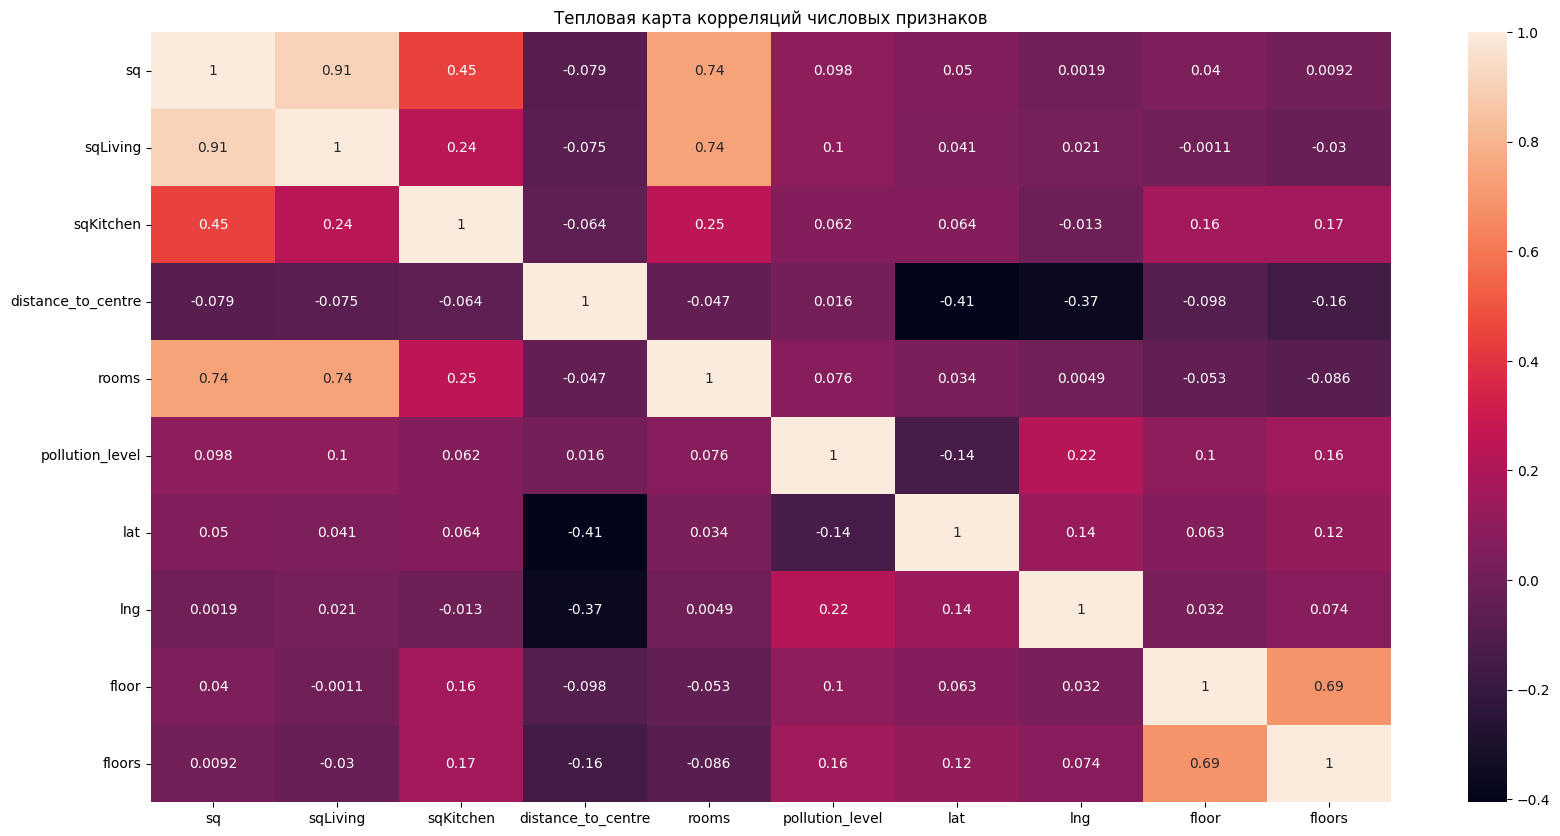

In [ ]:
x = ['sq', 'sqLiving', 'sqKitchen', 'distance_to_centre', 'rooms','pollution_level', 'lat', 'lng', 'floor','floors']
matrix = df[x].corr()
plt.figure(figsize=(20, 10))
sns.heatmap(matrix, annot=True)
plt.title('Тепловая карта корреляций числовых признаков')

Text(0, 0.5, 'Количество')

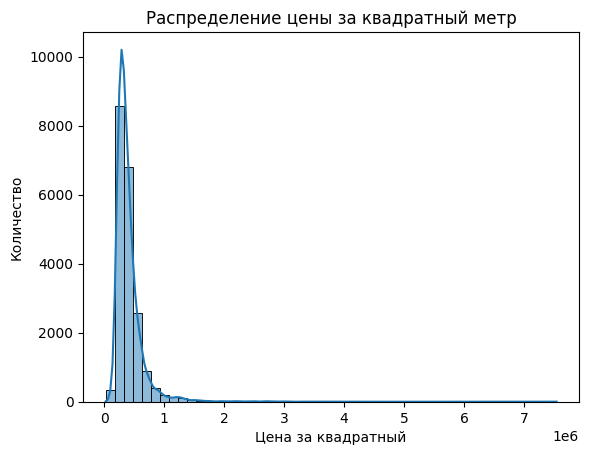

In [ ]:
df["cost_per_m2"] = df["cost"] / df["sq"]
sns.histplot(df["cost_per_m2"], bins=50, kde=True)
plt.title("Распределение цены за квадратный метр")
plt.xlabel("Цена за квадратный")
plt.ylabel("Количество")

Text(0, 0.5, 'Количество квартир')

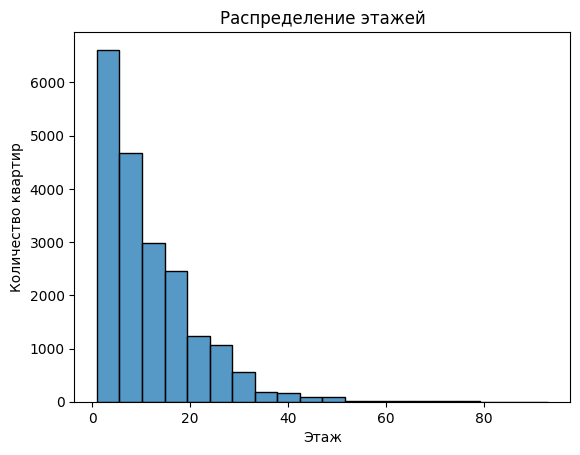

In [ ]:
sns.histplot(df["floor"], bins=20)
plt.title("Распределение этажей")
plt.xlabel("Этаж")
plt.ylabel("Количество квартир")

Text(0, 0.5, 'Количество домов')

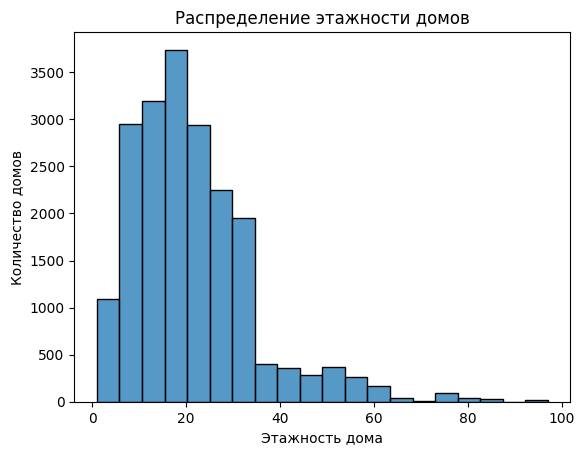

In [ ]:
sns.histplot(df["floors"], bins=20)
plt.title("Распределение этажности домов")
plt.xlabel("Этажность дома")
plt.ylabel("Количество домов")

Text(0, 0.5, 'Количество квартир')

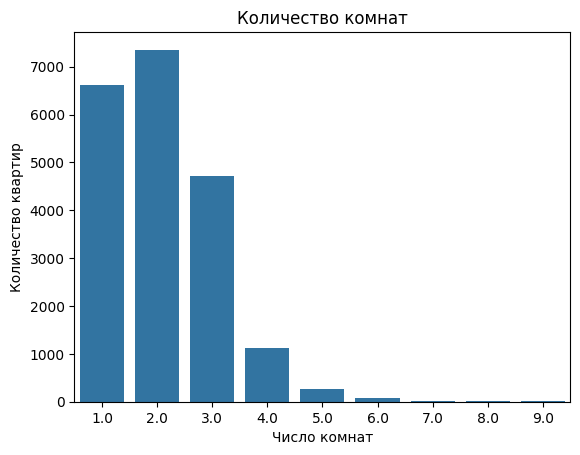

In [ ]:
sns.countplot(x="rooms", data=df)
plt.title("Количество комнат")
plt.xlabel("Число комнат")
plt.ylabel("Количество квартир")

Text(0.5, 1.0, 'Доля квартир(0) vs апартаментов(1)')

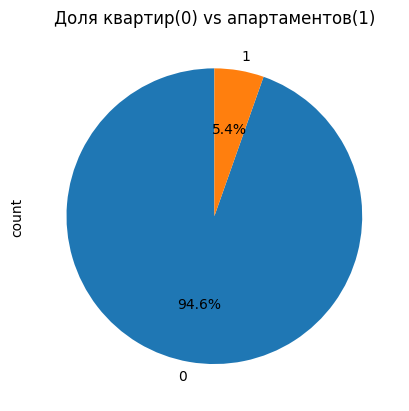

In [ ]:
df["isApartments"].value_counts().plot.pie(autopct="%1.1f%%", startangle=90)
plt.title("Доля квартир(0) vs апартаментов(1)")

Text(0, 0.5, 'Материал')

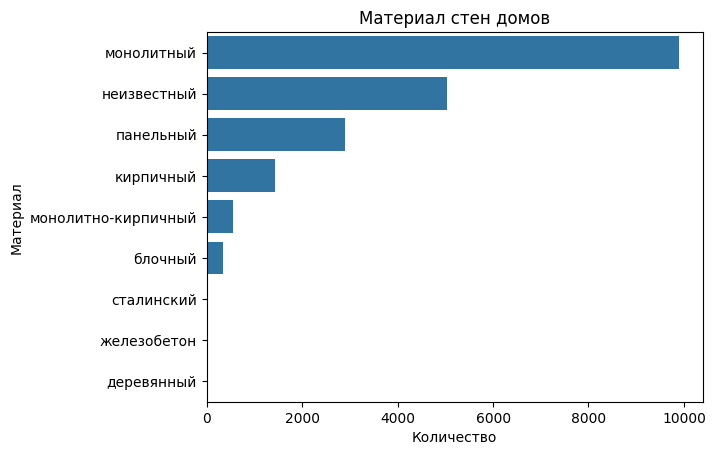

In [ ]:
sns.countplot(y="material", data=df1, order=df1["material"].value_counts().index)
plt.title("Материал стен домов")
plt.xlabel("Количество")
plt.ylabel("Материал")

Text(0, 0.5, 'Количество')

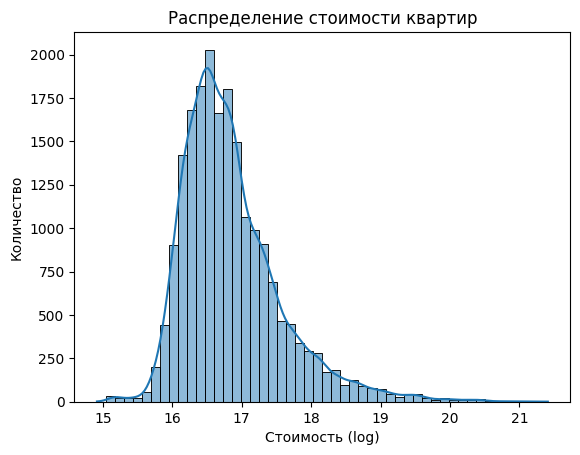

In [ ]:
sns.histplot(np.log(df["cost"]), bins=50, kde=True)
plt.title("Распределение стоимости квартир")
plt.xlabel("Стоимость (log)")
plt.ylabel("Количество")

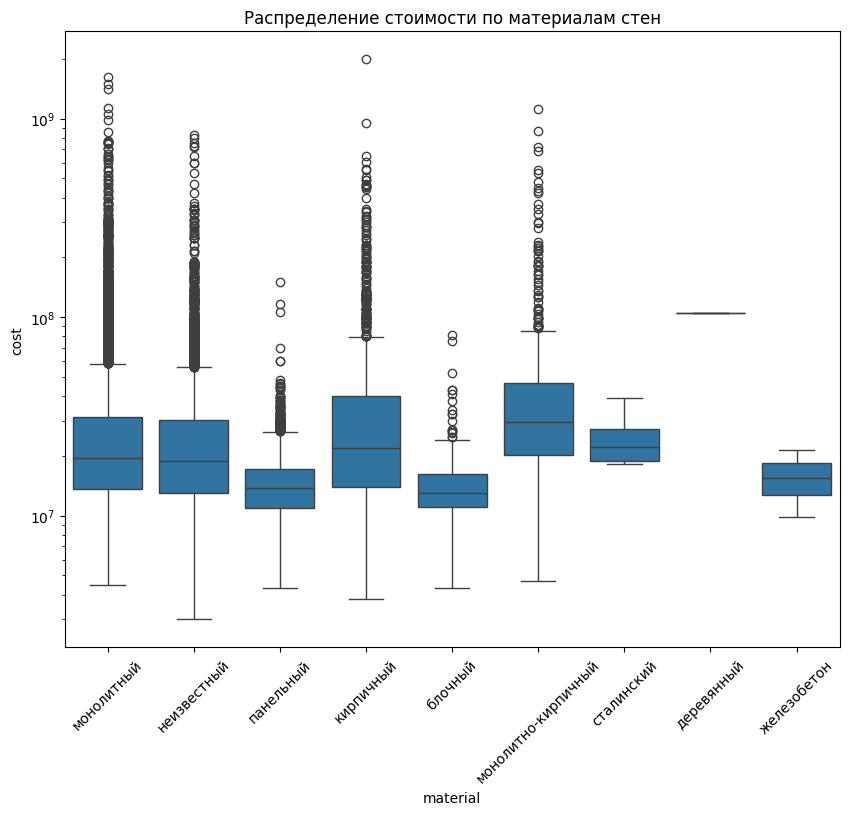

In [ ]:
plt.figure(figsize=(10, 8))
sns.boxplot(data=df1, x='material', y='cost')
plt.xticks(rotation=45)
plt.title('Распределение стоимости по материалам стен')
plt.yscale('log')

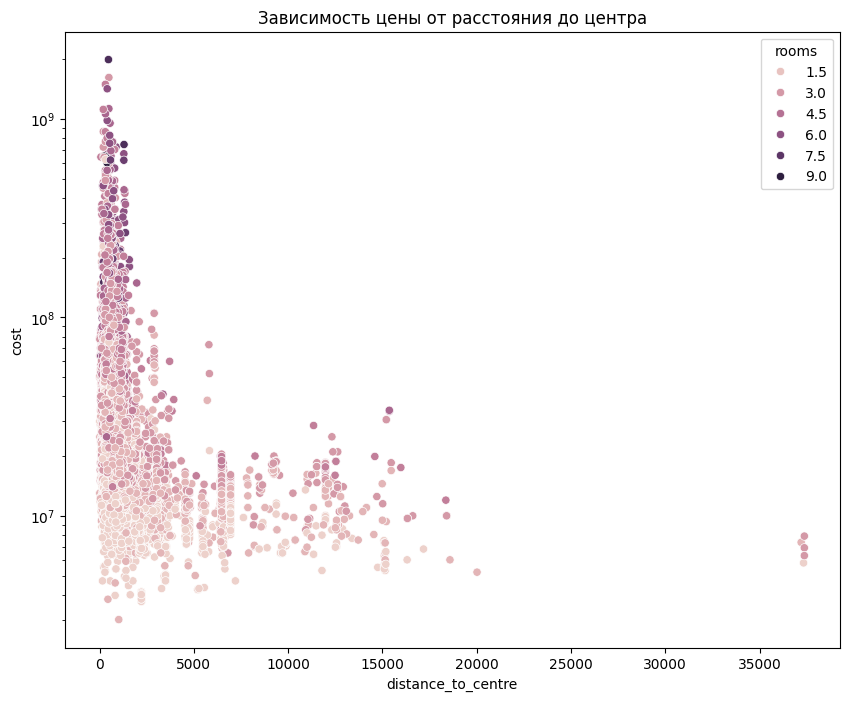

In [ ]:
plt.figure(figsize=(10, 8))
sns.scatterplot(data=df1, x='distance_to_centre', y='cost', hue='rooms')
plt.title('Зависимость цены от расстояния до центра')
plt.yscale('log')

Text(0, 0.5, 'Широта')

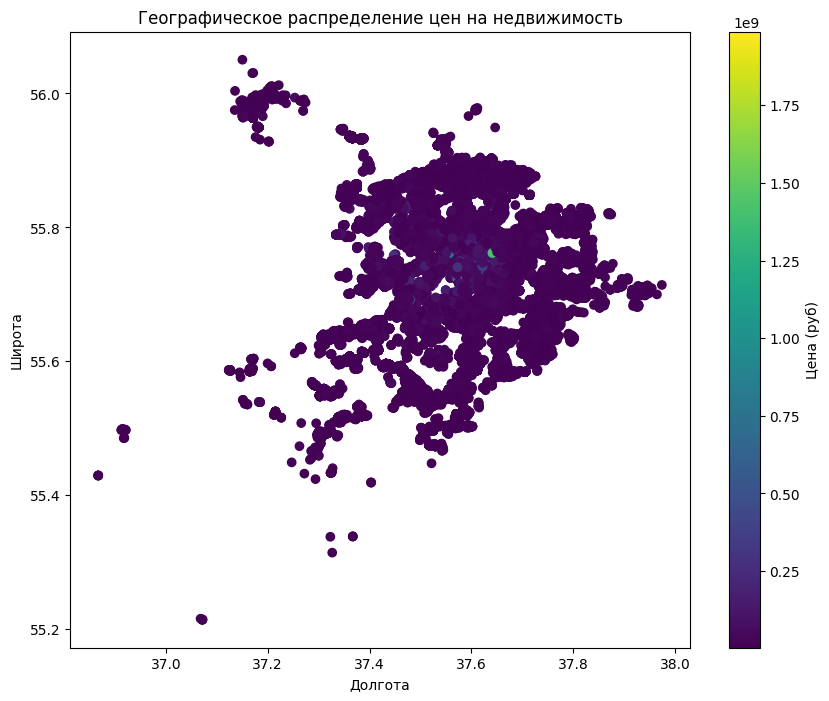

In [ ]:
plt.figure(figsize=(10, 8))
scatter = plt.scatter(df['lng'], df['lat'], c=df['cost'])
plt.colorbar(scatter, label='Цена (руб)')
plt.title('Географическое распределение цен на недвижимость')
plt.xlabel('Долгота')
plt.ylabel('Широта')

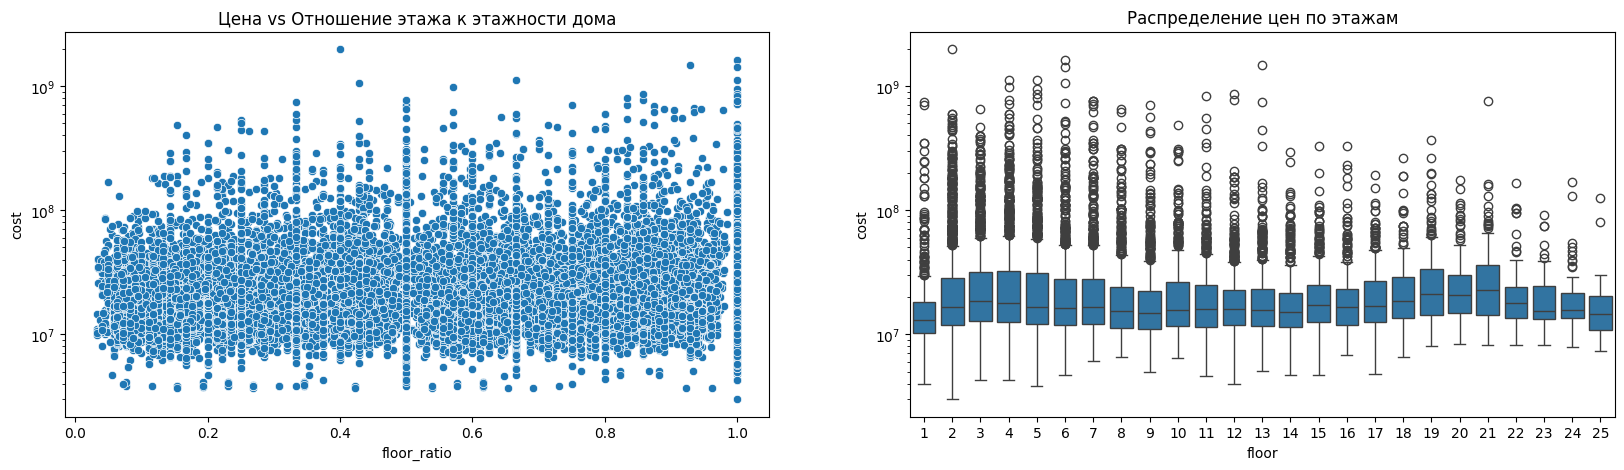

In [ ]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(20, 5))
df['floor_ratio'] = df['floor'] / df['floors']
sns.scatterplot(df, x='floor_ratio', y='cost', ax=ax1)
ax1.set_title('Цена vs Отношение этажа к этажности дома')
ax1.set_yscale('log')
sns.boxplot(data=df[df['floors'] <= 25], x='floor', y='cost', ax=ax2)
ax2.set_title('Распределение цен по этажам')
ax2.set_yscale('log')

Text(0.5, 0, 'Цена за кв.м')

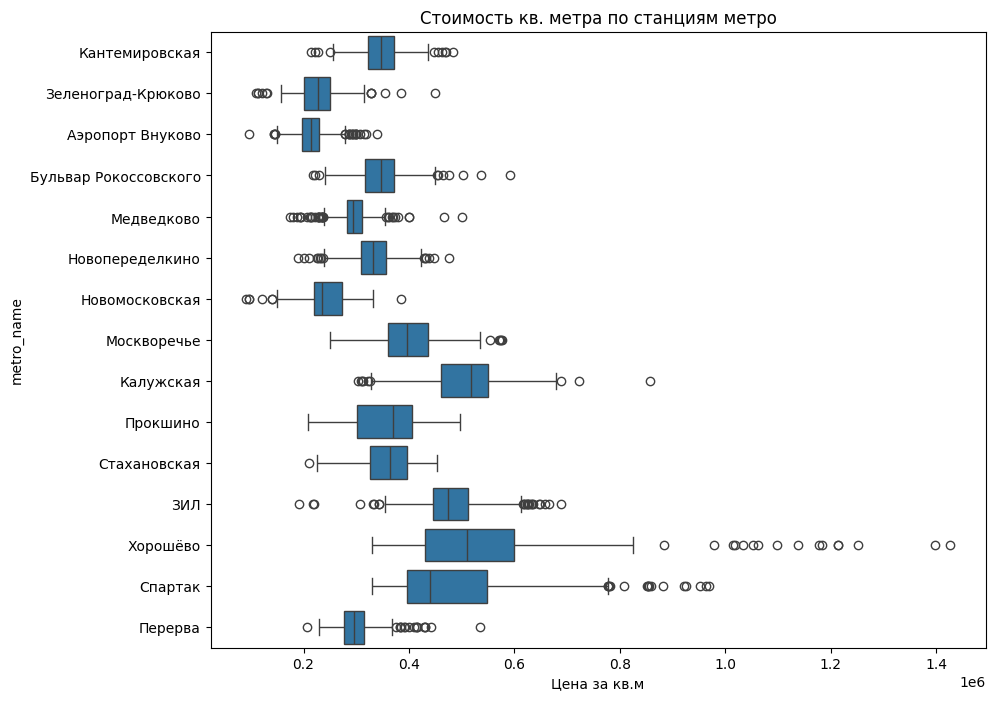

In [ ]:
df1['price_per_sqm'] = df1['cost'] / df1['sq']
top_metros = df1['metro_name'].value_counts().head(15).index
plt.figure(figsize=(10, 8))
sns.boxplot(data=df1[df1['metro_name'].isin(top_metros)], x='price_per_sqm', y='metro_name')
plt.title('Стоимость кв. метра по станциям метро')
plt.xlabel('Цена за кв.м')

Text(0.5, 1.02, 'Взаимосвязи между площадями и стоимостью')

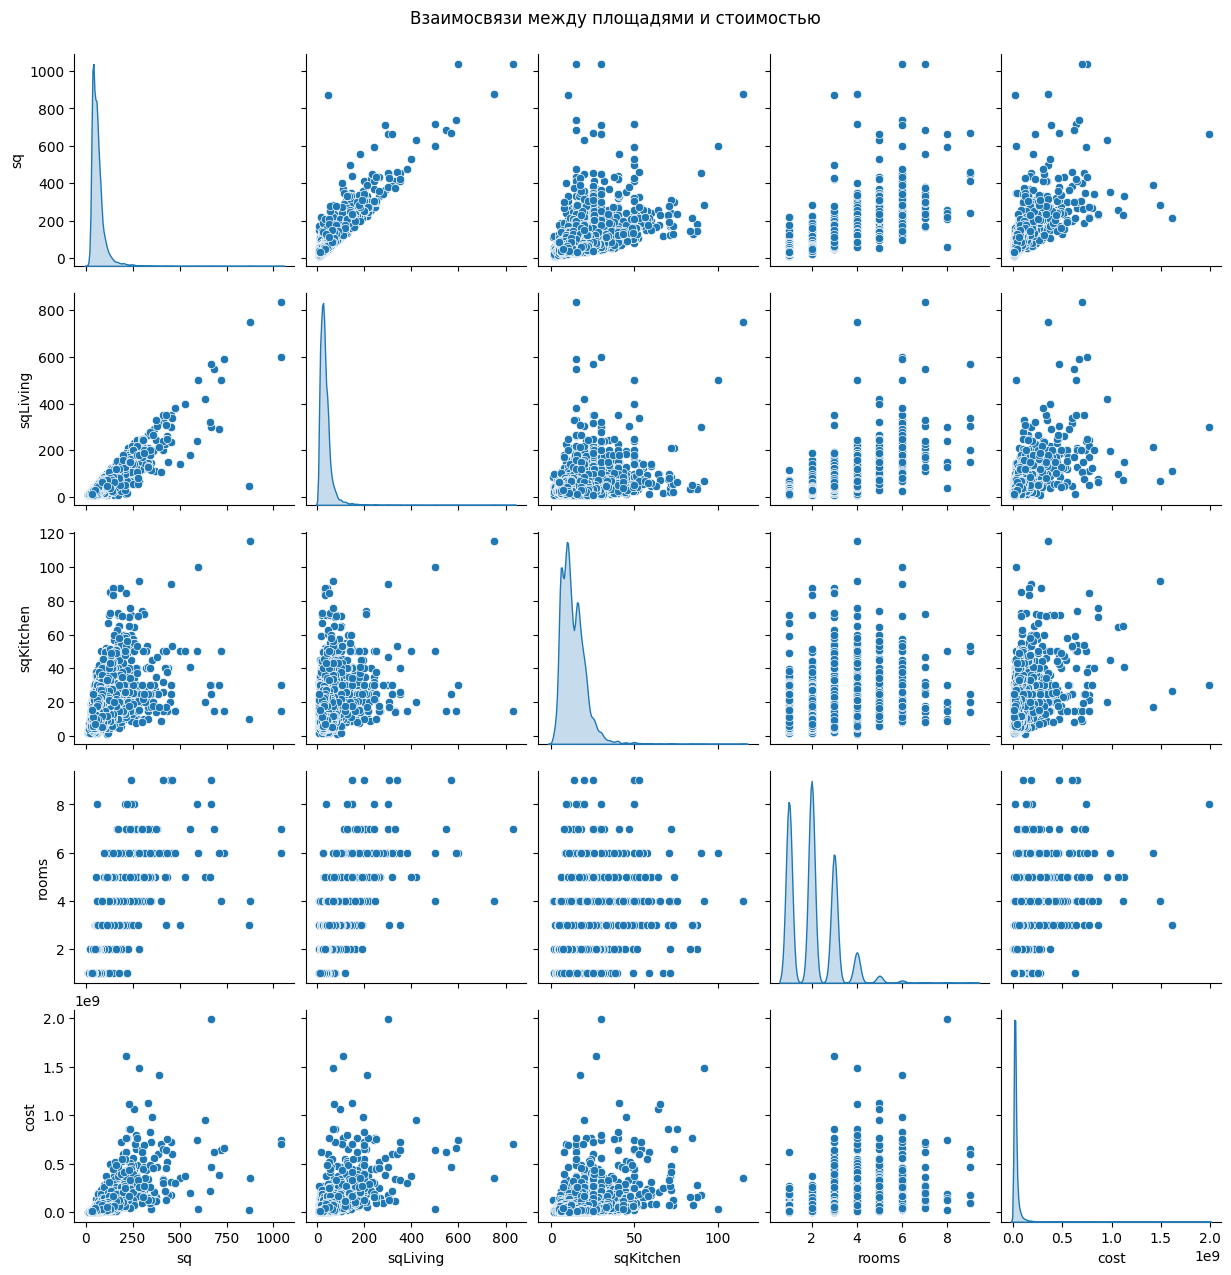

In [ ]:
lst = ['sq', 'sqLiving', 'sqKitchen', 'rooms', 'cost']
sns.pairplot(df[lst], diag_kind='kde') #документация: https://seaborn.pydata.org/generated/seaborn.pairplot.html
plt.suptitle('Взаимосвязи между площадями и стоимостью', y=1.02)

## Подготовка данных к МЛ

In [ ]:
from sklearn.preprocessing import StandardScaler, OneHotEncoder

In [ ]:
df = pd.read_csv("fin_dataset.csv")

**1. Удаляем лишние столбцы**

In [ ]:
df = df.drop(['Unnamed: 0', 'id', 'address', 'created', 'updated', 'district_lower', 'district_score', 'costlg', 'agent', 'source'], axis=1)

Также при мердже появилась пустая строка с нанами, удалим

In [ ]:
df = df.drop(20185)
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20185 entries, 0 to 20184
Data columns (total 16 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   floor               20185 non-null  int64  
 1   floors              20185 non-null  int64  
 2   sq                  20185 non-null  float64
 3   sqLiving            20185 non-null  float64
 4   sqKitchen           20185 non-null  float64
 5   cost                20185 non-null  int64  
 6   lat                 20185 non-null  float64
 7   lng                 20185 non-null  float64
 8   isNew               20185 non-null  object 
 9   rooms               20185 non-null  float64
 10  isApartments        20185 non-null  object 
 11  material            20185 non-null  object 
 12  distance_to_centre  20185 non-null  float64
 13  metro_name          20185 non-null  object 
 14  district            20185 non-null  object 
 15  pollution_level     20185 non-null  object 
dtypes: f

In [ ]:
df1 = df.copy()

**2. Кодирование категориальных признаков**

**2.1 Метро**

Перед тем, как воспользовать OneHot, сократим количество названий станций метро, поменяв их на названия веток. (иначе добавиться слишком большое количество новых столбцов). Для этого сначала создадим общий словарь. тут мы использвоали нейросеть чтобы быстро сделать данный словарь, так как руками это псиать смысла нет

In [ ]:
metro_line_map = {
    'Новодачная': 'МЦД/ЖД',
    'Рабочий посёлок': 'МЦД/ЖД',
    'Покровское': 'МЦД/ЖД',
    'Немчиновка': 'МЦД/ЖД',
    'Грачёвская': 'МЦД/ЖД',
    'Зеленоград-Крюково': 'МЦД/ЖД',
    'Битца': 'МЦД/ЖД',
    'Щербинка': 'МЦД/ЖД',
    'Бескудниково': 'МЦД/ЖД',
    'Бунинская Аллея': 'Бутовская',
    'Преображенская площадь': 'Сокольническая',
    'Серп и Молот': 'Калининско-Солнцевская',
    'Моссельмаш': 'МЦД/ЖД',
    'Силикатная': 'МЦД/ЖД',
    'Солнечная': 'Калининско-Солнцевская',
    'Бутово': 'МЦД/ЖД',
    'Курьяново': 'МЦД/ЖД',
    'Сетунь': 'МЦД/ЖД',
    'Тестовская (Москва-Сити)': 'Филёвская',
    'Фирсановская': 'МЦД/ЖД',
    'Вешняки': 'МЦД/ЖД',
    'Санино': 'МЦД/ЖД',
    'Москворечье': 'МЦД/ЖД',
    'Поклонная': 'Калининско-Солнцевская',
    'Москва-Сити': 'Филёвская',
    'Люберцы': 'МЦД/ЖД',
    'Трикотажная': 'МЦД/ЖД',
    'Сортировочная': 'МЦД/ЖД',
    'Мичуринец': 'МЦД/ЖД',
    'Матвеевская': 'МЦД/ЖД',
    'Москва-Товарная': 'МЦД/ЖД',
    'Переделкино': 'МЦД/ЖД',
    'Дегунино': 'МЦД/ЖД',
    'Депо': 'МЦД/ЖД',
    'Красный Строитель': 'МЦД/ЖД',
    'Остафьево': 'МЦД/ЖД',
    'Реутов': 'МЦД/ЖД',
    'Водники': 'МЦД/ЖД',
    'Кокошкино': 'МЦД/ЖД',
    'Мещерская': 'МЦД/ЖД',
    'Очаково': 'МЦД/ЖД',
    'Панки': 'МЦД/ЖД',
    'Митьково': 'МЦД/ЖД',
    'Молжаниново': 'МЦД/ЖД',
    'Новоподрезково': 'МЦД/ЖД',
    'Черкизовская': 'Сокольническая',
    'Перерва': 'Люблинско-Дмитровская',
    'Сколково': 'МЦД/ЖД',
    'Павшино': 'МЦД/ЖД',
    'Кусково': 'МЦД/ЖД',
    'Победа': 'МЦД/ЖД',
    'Апрелевка': 'МЦД/ЖД',
    'Подольск': 'МЦД/ЖД',
    'Химки': 'МЦД/ЖД',
    'Калитники': 'МЦД/ЖД',
    'Останкино': 'МЦД/ЖД',
    'Плющево': 'МЦД/ЖД',
    'Пенягино': 'МЦД/ЖД',
    'Гражданская': 'МЦД/ЖД',
    'Красный Балтиец': 'МЦД/ЖД',
    'Площадь трёх вокзалов': 'Кольцевая',
    'Университет Дружбы Народов': 'Калужско-Рижская',
    'Чухлинка': 'МЦД/ЖД',
    'Ухтомская': 'МЦД/ЖД',
    'Марк': 'МЦД/ЖД',
    'Долгопрудная': 'МЦД/ЖД',
    'Хлебниково': 'МЦД/ЖД',
    'Толстопальцево': 'МЦД/ЖД',
    'Подрезково': 'МЦД/ЖД',
    'Внуково': 'МЦД/ЖД',
    'Сокольники': 'Сокольническая',
    'Проспект Мира': 'Кольцевая',
    'Сокольническая': 'Сокольническая',
    'Красносельская': 'Сокольническая',
    'Комсомольская': 'Сокольническая',
    'Красные Ворота': 'Сокольническая',
    'Чистые пруды': 'Сокольническая',
    'Лубянка': 'Сокольническая',
    'Охотный Ряд': 'Сокольническая',
    'Библиотека им. Ленина': 'Сокольническая',
    'Кропоткинская': 'Сокольническая',
    'Парк культуры': 'Сокольническая',
    'Фрунзенская': 'Сокольническая',
    'Спортивная': 'Сокольническая',
    'Воробьёвы горы': 'Сокольническая',
    'Университет': 'Сокольническая',
    'Проспект Вернадского': 'Сокольническая',
    'Юго-Западная': 'Сокольническая',
    'Тропарёво': 'Сокольническая',
    'Румянцево': 'Сокольническая',
    'Саларьево': 'Сокольническая',
    'Филатов Луг': 'Сокольническая',
    'Прокшино': 'Сокольническая',
    'Ольховая': 'Сокольническая',
    'Новомосковская': 'Сокольническая',
    'Потапово': 'Сокольническая',
    'Ховрино': 'Замоскворецкая',
    'Беломорская': 'Замоскворецкая',
    'Речной вокзал': 'Замоскворецкая',
    'Водный стадион': 'Замоскворецкая',
    'Войковская': 'Замоскворецкая',
    'Сокол': 'Замоскворецкая',
    'Аэропорт': 'Замоскворецкая',
    'Динамо': 'Замоскворецкая',
    'Белорусская': 'Замоскворецкая',
    'Маяковская': 'Замоскворецкая',
    'Тверская': 'Замоскворецкая',
    'Театральная': 'Замоскворецкая',
    'Новокузнецкая': 'Замоскворецкая',
    'Павелецкая': 'Замоскворецкая',
    'Автозаводская': 'Замоскворецкая',
    'Технопарк': 'Замоскворецкая',
    'Коломенская': 'Замоскворецкая',
    'Каширская': 'Замоскворецкая',
    'Кантемировская': 'Замоскворецкая',
    'Царицыно': 'Замоскворецкая',
    'Орехово': 'Замоскворецкая',
    'Домодедовская': 'Замоскворецкая',
    'Красногвардейская': 'Замоскворецкая',
    'Алма-Атинская': 'Замоскворецкая',
    'Пятницкое шоссе': 'Арбатско-Покровская',
    'Митино': 'Арбатско-Покровская',
    'Волоколамская': 'Арбатско-Покровская',
    'Мякинино': 'Арбатско-Покровская',
    'Строгино': 'Арбатско-Покровская',
    'Крылатское': 'Арбатско-Покровская',
    'Молодёжная': 'Арбатско-Покровская',
    'Кунцевская': 'Арбатско-Покровская',
    'Славянский бульвар': 'Арбатско-Покровская',
    'Парк Победы': 'Арбатско-Покровская',
    'Киевская': 'Арбатско-Покровская',
    'Смоленская': 'Арбатско-Покровская',
    'Арбатская': 'Арбатско-Покровская',
    'Площадь Революции': 'Арбатско-Покровская',
    'Курская': 'Арбатско-Покровская',
    'Бауманская': 'Арбатско-Покровская',
    'Электрозаводская': 'Арбатско-Покровская',
    'Семёновская': 'Арбатско-Покровская',
    'Партизанская': 'Арбатско-Покровская',
    'Измайловская': 'Арбатско-Покровская',
    'Первомайская': 'Арбатско-Покровская',
    'Щёлковская': 'Арбатско-Покровская',
    'Пионерская': 'Филёвская',
    'Филёвский парк': 'Филёвская',
    'Багратионовская': 'Филёвская',
    'Фили': 'Филёвская',
    'Кутузовская': 'Филёвская',
    'Студенческая': 'Филёвская',
    'Международная': 'Филёвская',
    'Выставочная': 'Филёвская',
    'Александровский сад': 'Филёвская',
    'Октябрьская': 'Кольцевая',
    'Добрынинская': 'Кольцевая',
    'Таганская': 'Кольцевая',
    'Новослободская': 'Кольцевая',
    'Краснопресненская': 'Кольцевая',
    'Медведково': 'Калужско-Рижская',
    'Бабушкинская': 'Калужско-Рижская',
    'Свиблово': 'Калужско-Рижская',
    'Ботанический сад': 'Калужско-Рижская',
    'ВДНХ': 'Калужско-Рижская',
    'Алексеевская': 'Калужско-Рижская',
    'Рижская': 'Калужско-Рижская',
    'Сухаревская': 'Калужско-Рижская',
    'Тургеневская': 'Калужско-Рижская',
    'Китай-город': 'Калужско-Рижская',
    'Третьяковская': 'Калужско-Рижская',
    'Шаболовская': 'Калужско-Рижская',
    'Ленинский проспект': 'Калужско-Рижская',
    'Академическая': 'Калужско-Рижская',
    'Профсоюзная': 'Калужско-Рижская',
    'Новые Черёмушки': 'Калужско-Рижская',
    'Калужская': 'Калужско-Рижская',
    'Беляево': 'Калужско-Рижская',
    'Коньково': 'Калужско-Рижская',
    'Тёплый Стан': 'Калужско-Рижская',
    'Ясенево': 'Калужско-Рижская',
    'Новоясеневская': 'Калужско-Рижская',
    'Планерная': 'Таганско-Краснопресненская',
    'Сходненская': 'Таганско-Краснопресненская',
    'Тушинская': 'Таганско-Краснопресненская',
    'Спартак': 'Таганско-Краснопресненская',
    'Щукинская': 'Таганско-Краснопресненская',
    'Октябрьское поле': 'Таганско-Краснопресненская',
    'Полежаевская': 'Таганско-Краснопресненская',
    'Беговая': 'Таганско-Краснопресненская',
    'Улица 1905 года': 'Таганско-Краснопресненская',
    'Баррикадная': 'Таганско-Краснопресненская',
    'Пушкинская': 'Таганско-Краснопресненская',
    'Кузнецкий мост': 'Таганско-Краснопресненская',
    'Пролетарская': 'Таганско-Краснопресненская',
    'Волгоградский проспект': 'Таганско-Краснопресненская',
    'Текстильщики': 'Таганско-Краснопресненская',
    'Кузьминки': 'Таганско-Краснопресненская',
    'Рязанский проспект': 'Таганско-Краснопресненская',
    'Выхино': 'Таганско-Краснопресненская',
    'Лермонтовский проспект': 'Таганско-Краснопресненская',
    'Жулебино': 'Таганско-Краснопресненская',
    'Котельники': 'Таганско-Краснопресненская',
    'Новокосино': 'Калининско-Солнцевская',
    'Новогиреево': 'Калининско-Солнцевская',
    'Перово': 'Калининско-Солнцевская',
    'Шоссе Энтузиастов': 'Калининско-Солнцевская',
    'Авиамоторная': 'Калининско-Солнцевская',
    'Площадь Ильича': 'Калининско-Солнцевская',
    'Марксистская': 'Калининско-Солнцевская',
    'Деловой центр': 'Калининско-Солнцевская',
    'Минская': 'Калининско-Солнцевская',
    'Ломоносовский проспект': 'Калининско-Солнцевская',
    'Раменки': 'Калининско-Солнцевская',
    'Мичуринский проспект': 'Калининско-Солнцевская',
    'Озёрная': 'Калининско-Солнцевская',
    'Говорово': 'Калининско-Солнцевская',
    'Солнцево': 'Калининско-Солнцевская',
    'Боровское шоссе': 'Калининско-Солнцевская',
    'Новопеределкино': 'Калининско-Солнцевская',
    'Рассказовка': 'Калининско-Солнцевская',
    'Пыхтино': 'Калининско-Солнцевская',
    'Аэропорт Внуково': 'Калининско-Солнцевская',
    'Алтуфьево': 'Серпуховско-Тимирязевская',
    'Бибирево': 'Серпуховско-Тимирязевская',
    'Отрадное': 'Серпуховско-Тимирязевская',
    'Владыкино': 'Серпуховско-Тимирязевская',
    'Петровско-Разумовская': 'Серпуховско-Тимирязевская',
    'Тимирязевская': 'Серпуховско-Тимирязевская',
    'Дмитровская': 'Серпуховско-Тимирязевская',
    'Савёловская': 'Серпуховско-Тимирязевская',
    'Менделеевская': 'Серпуховско-Тимирязевская',
    'Цветной бульвар': 'Серпуховско-Тимирязевская',
    'Чеховская': 'Серпуховско-Тимирязевская',
    'Боровицкая': 'Серпуховско-Тимирязевская',
    'Полянка': 'Серпуховско-Тимирязевская',
    'Серпуховская': 'Серпуховско-Тимирязевская',
    'Тульская': 'Серпуховско-Тимирязевская',
    'Нагатинская': 'Серпуховско-Тимирязевская',
    'Нагорная': 'Серпуховско-Тимирязевская',
    'Нахимовский проспект': 'Серпуховско-Тимирязевская',
    'Севастопольская': 'Серпуховско-Тимирязевская',
    'Чертановская': 'Серпуховско-Тимирязевская',
    'Южная': 'Серпуховско-Тимирязевская',
    'Пражская': 'Серпуховско-Тимирязевская',
    'Улица Академика Янгеля': 'Серпуховско-Тимирязевская',
    'Аннино': 'Серпуховско-Тимирязевская',
    'Бульвар Дмитрия Донского': 'Серпуховско-Тимирязевская',
    'Физтех': 'Люблинско-Дмитровская',
    'Лианозово': 'Люблинско-Дмитровская',
    'Яхромская': 'Люблинско-Дмитровская',
    'Селигерская': 'Люблинско-Дмитровская',
    'Верхние Лихоборы': 'Люблинско-Дмитровская',
    'Окружная': 'Люблинско-Дмитровская',
    'Фонвизинская': 'Люблинско-Дмитровская',
    'Бутырская': 'Люблинско-Дмитровская',
    'Марьина Роща': 'Люблинско-Дмитровская',
    'Достоевская': 'Люблинско-Дмитровская',
    'Трубная': 'Люблинско-Дмитровская',
    'Сретенский бульвар': 'Люблинско-Дмитровская',
    'Чкаловская': 'Люблинско-Дмитровская',
    'Римская': 'Люблинско-Дмитровская',
    'Крестьянская застава': 'Люблинско-Дмитровская',
    'Дубровка': 'Люблинско-Дмитровская',
    'Кожуховская': 'Люблинско-Дмитровская',
    'Печатники': 'Люблинско-Дмитровская',
    'Волжская': 'Люблинско-Дмитровская',
    'Люблино': 'Люблинско-Дмитровская',
    'Братиславская': 'Люблинско-Дмитровская',
    'Марьино': 'Люблинско-Дмитровская',
    'Борисово': 'Люблинско-Дмитровская',
    'Шипиловская': 'Люблинско-Дмитровская',
    'Зябликово': 'Люблинско-Дмитровская',
    'Петровский парк': 'Большая кольцевая',
    'ЦСКА': 'Большая кольцевая',
    'Хорошёвская': 'Большая кольцевая',
    'Шелепиха': 'Большая кольцевая',
    'Мнёвники': 'Большая кольцевая',
    'Народное Ополчение': 'Большая кольцевая',
    'Терехово': 'Большая кольцевая',
    'Давыдково': 'Большая кольцевая',
    'Аминьевская': 'Большая кольцевая',
    'Новаторская': 'Большая кольцевая',
    'Воронцовская': 'Большая кольцевая',
    'Зюзино': 'Большая кольцевая',
    'Каховская': 'Большая кольцевая',
    'Варшавская': 'Большая кольцевая',
    'Кленовый бульвар': 'Большая кольцевая',
    'Нагатинский Затон': 'Большая кольцевая',
    'Нижегородская': 'Большая кольцевая',
    'Стахановская': 'Большая кольцевая',
    'Окская': 'Большая кольцевая',
    'Юго-Восточная': 'Большая кольцевая',
    'Косино': 'Большая кольцевая',
    'Улица Дмитриевского': 'Большая кольцевая',
    'Лухмановская': 'Большая кольцевая',
    'Некрасовка': 'Большая кольцевая',
    'Лефортово': 'Большая кольцевая',
    'Битцевский парк': 'Бутовская',
    'Лесопарковая': 'Бутовская',
    'Улица Старокачаловская': 'Бутовская',
    'Улица Скобелевская': 'Бутовская',
    'Бульвар Адмирала Ушакова': 'Бутовская',
    'Улица Горчакова': 'Бутовская',
    'Ростокино': 'МЦК',
    'Белокаменная': 'МЦК',
    'Бульвар Рокоссовского': 'МЦК',
    'Локомотив': 'МЦК',
    'Измайлово': 'МЦК',
    'Соколиная гора': 'МЦК',
    'Андроновка': 'МЦК',
    'Новохохловская': 'МЦК',
    'Угрешская': 'МЦК',
    'ЗИЛ': 'МЦК',
    'Верхние Котлы': 'МЦК',
    'Крымская': 'МЦК',
    'Площадь Гагарина': 'МЦК',
    'Лужники': 'МЦК',
    'Хорошёво': 'МЦК',
    'Зорге': 'МЦК',
    'Панфиловская': 'МЦК',
    'Стрешнево': 'МЦК',
    'Балтийская': 'МЦК',
    'Коптево': 'МЦК',
    'Лихоборы': 'МЦК',
    'Вавиловская': 'Троицкая',
    'Генерала Тюленева': 'Троицкая',
    'Тютчевская': 'Троицкая',
    'Корниловская': 'Троицкая',
    'Коммунарка': 'Троицкая'}

Преобразуем:

In [ ]:
df['metro_name'] = df['metro_name'].map(metro_line_map)

**2.2 Сам OneHotEncoder** по [документации](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.OneHotEncoder.html)

In [ ]:
y = ['metro_name', 'material', 'district']
oht = OneHotEncoder(sparse_output=False,dtype=int)
enc = oht.fit_transform(df[y])
new = pd.DataFrame(enc, columns=oht.get_feature_names_out(y))

Удалим старые столбцы и добавим новые, но уже закодированные.

In [ ]:
df = df.drop(y, axis=1)
df = pd.concat([df, new], axis=1)

**3. Работа с бинарными и вещественными признаками**

**3.1 Бинарные преобразуем в 0 и 1 (меняем тип данных)**

In [ ]:
df['isNew'] = df['isNew'].astype(int)
df['isApartments'] = df['isApartments'].astype(int)

**3.2 Меняем тип данных в колонке с уровнем загрязнения воздуха в районе**

In [ ]:
df['pollution_level'].value_counts()

,count
pollution_level,
неизвестно,6521
8.0,2872
6.0,2618
7.0,2441
5.0,2238
9.0,2154
4.0,806
10.0,364
3.0,171


Пустые значения, помеченные "неизвестно" заменим на медианное значение.

In [ ]:
df['pollution_level'] = df['pollution_level'].replace('неизвестно', np.nan)
df['pollution_level'] = pd.to_numeric(df['pollution_level'], errors='coerce')
df['pollution_level'] = df['pollution_level'].fillna(df['pollution_level'].median())

сохарним датафрейм (он будет нужен в кластеризации)

In [ ]:
df_original = df.copy()

**3.3 Масштабирование вещественных признаков**

In [ ]:
x = ['sq', 'sqLiving', 'sqKitchen', 'distance_to_centre', 'rooms',
'pollution_level', 'lat', 'lng', 'floor','floors']
scaler = StandardScaler()
df_scaled = df.copy()
df_scaled[x] = scaler.fit_transform(df[x])

In [ ]:
df_f = df_scaled.copy()
df_f.to_csv('df_f.csv', index=False, encoding='utf-8-sig')